In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Matplotlib 不规则子图布局实验

## 一、实验目的

学习使用 `subplot2grid()` 创建不规则子图布局，理解 `rowspan` 和 `colspan` 的作用，并比较不同网格结构下子图的排列方式。

## 二、实验原理

`subplot2grid(shape, loc, rowspan=1, colspan=1)` 会先把画布划分为虚拟网格，再从指定位置创建子图。其中：

- `shape` 表示网格的行数和列数；
- `loc` 表示子图的起始位置，行列索引从 0 开始；
- `rowspan` 表示纵向跨越的行数；
- `colspan` 表示横向跨越的列数。

与普通 `subplot()` 相比，`subplot2grid()` 可以创建大小不同、形状不规则的子图。

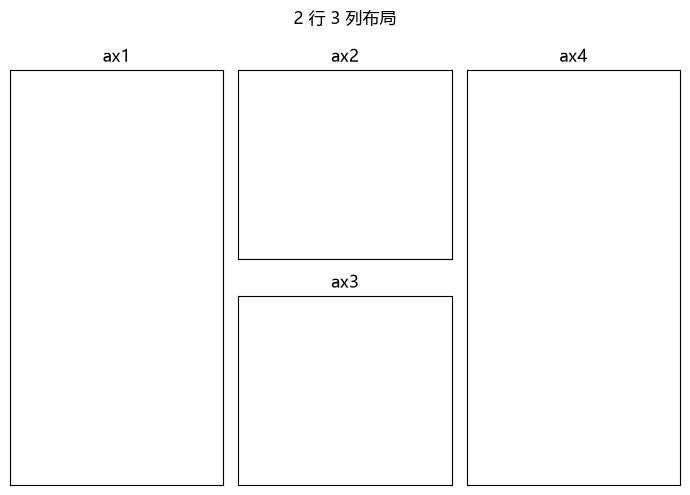

In [2]:
# 2 行 3 列的不规则子图布局
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(7, 5))

# 左右子图各纵向跨越 2 行，中间子图各占 1 个网格
ax1 = plt.subplot2grid((2, 3), (0, 0), rowspan=2)
ax2 = plt.subplot2grid((2, 3), (0, 1))
ax3 = plt.subplot2grid((2, 3), (1, 1))
ax4 = plt.subplot2grid((2, 3), (0, 2), rowspan=2)

for index, axis in enumerate((ax1, ax2, ax3, ax4), start=1):
    axis.set_title(f"ax{index}")
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle("2 行 3 列布局")
fig.tight_layout()
plt.show()

## 三、实验内容一：2 行 3 列布局

本实验将画布划分为 2 行 3 列：左侧 `ax1` 和右侧 `ax4` 各纵向跨越 2 行，中间的 `ax2` 和 `ax3` 各占一个网格。

布局结构如下：

| ax1（跨 2 行） | ax2 | ax4（跨 2 行） |
| --- | --- | --- |
|  | ax3 |  |

这种布局适合把两个较大的图形放在左右两侧，把两个较小的辅助图形放在中间。

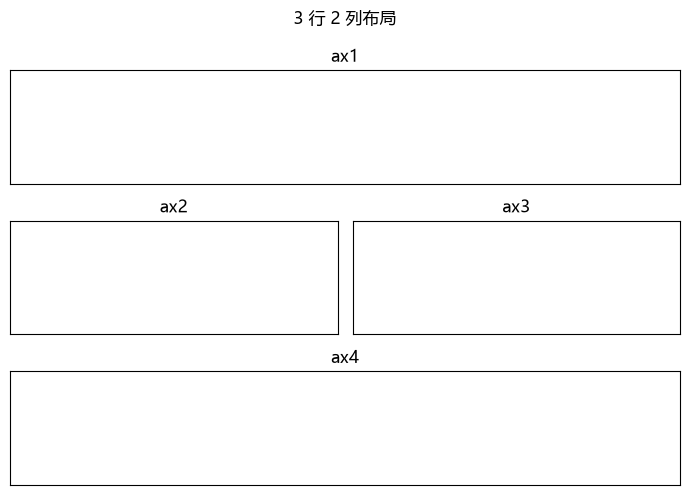

In [3]:
# 创建一个空的 DataFrame，后续可用于存放数据
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 创建一个 7×5 英寸的绘图画布
df = pd.DataFrame()

fig = plt.figure(figsize=(7, 5))

# 使用 subplot2grid 构建不规则子图布局
# 布局：2 行 3 列
# 左侧子图占据两行，其中（0, 0）位置是左上角
ax1 = plt.subplot2grid((3, 2), (0, 0), colspan=2)
# 中上方子图占据一个网格，（0, 1）位置是中上方
ax2 = plt.subplot2grid((3, 2), (1,0 ))
# 中下方子图占据一个网格,（1, 1）位置是中下方
ax3 = plt.subplot2grid((3, 2), (1, 1))
# 右侧子图占据两行，（0, 2）位置是右上角
ax4 = plt.subplot2grid((3, 2), (2, 0), colspan=2)

for index, axis in enumerate((ax1, ax2, ax3, ax4), start=1):
    axis.set_title(f"ax{index}")
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle("3 行 2 列布局")
fig.tight_layout()
plt.show()

## 四、实验内容二：3 行 2 列布局

第二种布局将画布划分为 3 行 2 列：顶部 `ax1` 横向跨越 2 列，中间的 `ax2` 和 `ax3` 分别占据一列，底部 `ax4` 再次横向跨越 2 列。

布局结构如下：

| ax1（跨 2 列） |
| --- |
| ax2 | ax3 |
| ax4（跨 2 列） |

## 五、结果分析

两段代码都成功创建了 4 个坐标轴对象。第一种布局突出左右两侧的区域，第二种布局突出上下两条横向区域。由此可见，`rowspan` 适合控制纵向扩展，`colspan` 适合控制横向扩展。

## 六、实验总结

`subplot2grid()` 能够突破等尺寸子图的限制，适合制作仪表盘、综合分析图和多指标展示页面。实际绘图时，只需在 `ax1`、`ax2`、`ax3` 和 `ax4` 上分别调用 `plot()`、`bar()` 或 `scatter()` 等方法即可填充数据。